# Week 9 - Multivariate Analysis, part 2

# 1. Lesson - no lesson this week

# 2. Weekly graph question

The graph below plots the first two principal component scores in a scatter plot.  What can be said about the three outliers in the upper left corner of the graph?  Is their first principal component score high or low?  What about their second principal component score?  What does that mean about their values in series_1, series_2, and series_3?  It seems to me that you can say something about series_3 (what can you say?) but you may have a harder time saying something about series_1 and series_2, and an almost impossible time saying anything about the relative values of series_1 and series_2.  Why is that?  How are series_1 and series_2 related, according to how they were created?  If you like, try drawing a pairplot for all three series and see what you get.

Overall, what are the advantages and disadvantages of the graph below?  Does it show anything interesting?

In [25]:
%pip install numpy pandas matplotlib scikit-learn seaborn


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


[0.79916477 0.18990532 0.01092991]
[[ 0.26541493  0.30096233  0.91595665]
 [ 0.60337553  0.6891417  -0.40127506]
 [ 0.75199261 -0.65917023 -0.00131519]]


Text(0, 0.5, 'Second Principal Component Score')

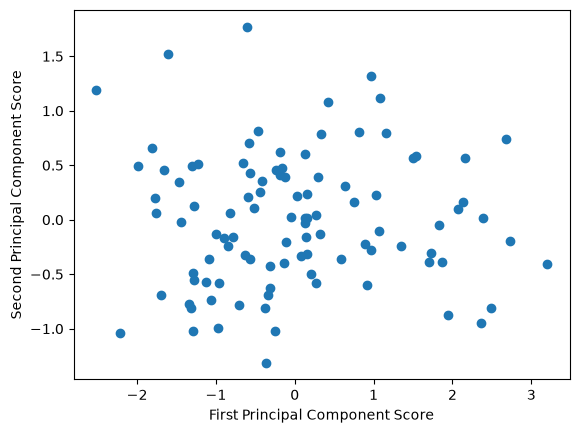

In [26]:
import numpy as np
import pandas as pd
from sklearn import decomposition
import matplotlib.pyplot as plt

np.random.seed(0)
num_points = 100
series_1 = np.random.normal(loc = 2, scale = 0.5, size = num_points)
series_2 = series_1 * (1 + np.random.normal(loc = 0, scale = 0.1, size = num_points))
series_3 = series_1 * (1 + np.random.normal(loc = 0, scale = 0.5, size = num_points))
df = pd.DataFrame({'ser1': series_1, 'ser2': series_2, 'ser3': series_3})
df = df - df.mean() # set mean to zero, so we don't have to subtract mean from the principal component scores

pca3 = decomposition.PCA(n_components = 3)
pca3.fit(df)
print(pca3.explained_variance_ratio_)
print(pca3.components_)

first_principal_component_score = df.dot(pca3.components_[0])
second_principal_component_score = df.dot(pca3.components_[1])
plt.scatter(first_principal_component_score, second_principal_component_score)
plt.xlabel("First Principal Component Score")
plt.ylabel("Second Principal Component Score")

# 3. Working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

Here are some types of analysis you can do:
Draw heatmaps.

Draw bubble plots.

Perform Principal Component Analysis to find out the directions in which the data varies.  Can you represent the data using only its projection onto its first principal component, using the methods described in Week 8?  How much of the variance would this capture?

Try performing linear regression analysis using different sets of features.  Which features seem most likely to be useful to predict other features?

Conclusions:
Explain what conclusions you would draw from this analysis: are the data what you expect? Are the data likely to be usable? If the data are not useable, find some new data!

Do you see any outliers? (Data points that are far from the rest of the data).

Does the Principal Component Analysis suggest a way to represent the data using fewer dimensions than usual - using its first one or two principal component scores, perhaps?

Try using your correlation information from previous weeks to help choose features for linear regression.

In this week's analysis, I explored my two selected datasets using correlation heatmaps, bubble plots, Principal Component Analysis, and linear regression.

For the Life Expectancy dataset, the correlation analysis helped identify relationships between life expectancy and other variables, including GDP, adult mortality, and schooling. These relationships provide useful information about how economic and health indicators are associated with life expectancy across different countries.

The bubble plot provided another way to examine relationships between multiple variables at the same time. PCA was also useful for understanding whether the dataset could be represented using fewer dimensions while preserving a significant amount of its variance.

For the Diabetes dataset, the numerical variables provided opportunities to explore relationships between patient and hospital-related information. However, some variables are categorical or represent identifiers, so they require careful consideration before applying PCA or regression.

I also examined the datasets for potential outliers. Some observations may differ significantly from the rest of the data because countries have different economic conditions, healthcare systems, and population characteristics.

Overall, both datasets provide useful information for further analysis. However, appropriate data cleaning, feature selection, and preprocessing are important to obtain meaningful results. These techniques will help me better understand the relationships within the datasets and determine which features are most useful for future analysis.

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
life = pd.read_csv("Life Expectancy Data.csv")
diabetes = pd.read_csv("diabetic_data.csv")

# Remove extra spaces from column names
life.columns = life.columns.str.strip()

print("Life Expectancy Dataset:")
display(life.head())

print("Diabetes Dataset:")
display(diabetes.head())

Life Expectancy Dataset:


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


Diabetes Dataset:


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


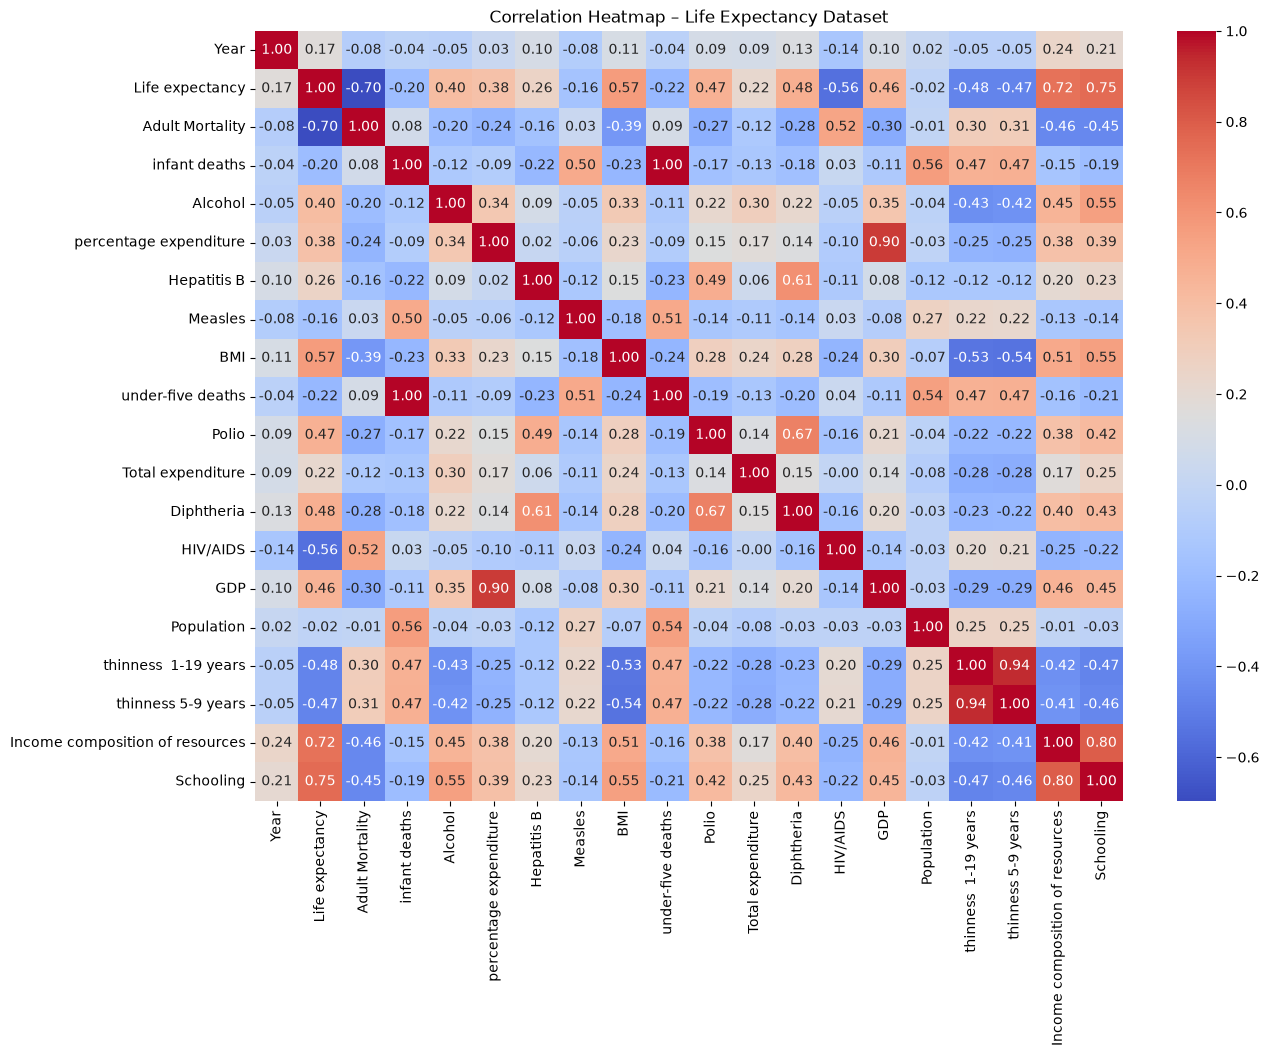

In [28]:
life_numeric = life.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))
sns.heatmap(
    life_numeric.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap – Life Expectancy Dataset")
plt.show()

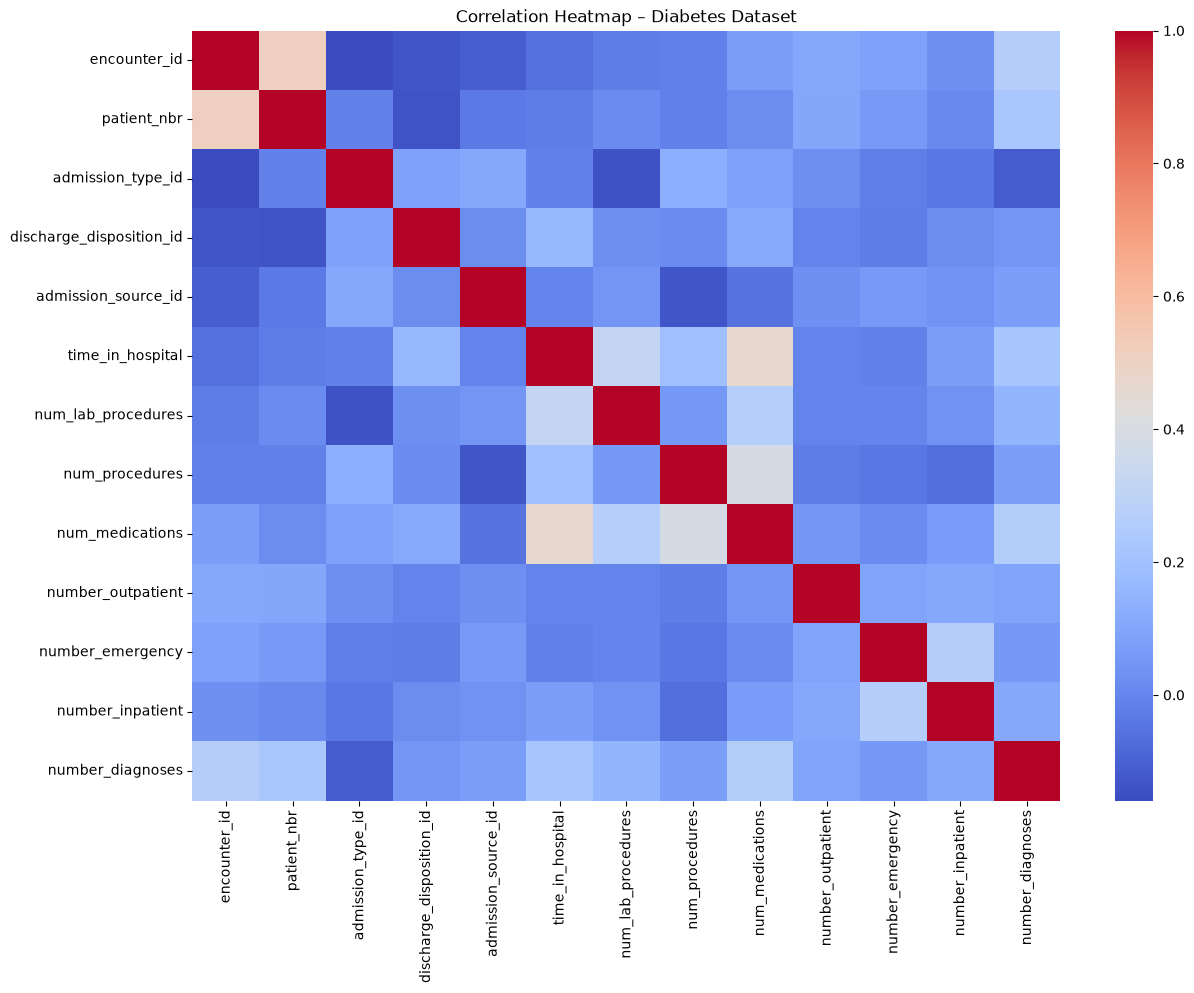

In [29]:
diabetes_numeric = diabetes.select_dtypes(include=np.number)

plt.figure(figsize=(14, 10))
sns.heatmap(
    diabetes_numeric.corr(),
    cmap="coolwarm",
    annot=False
)

plt.title("Correlation Heatmap – Diabetes Dataset")
plt.show()

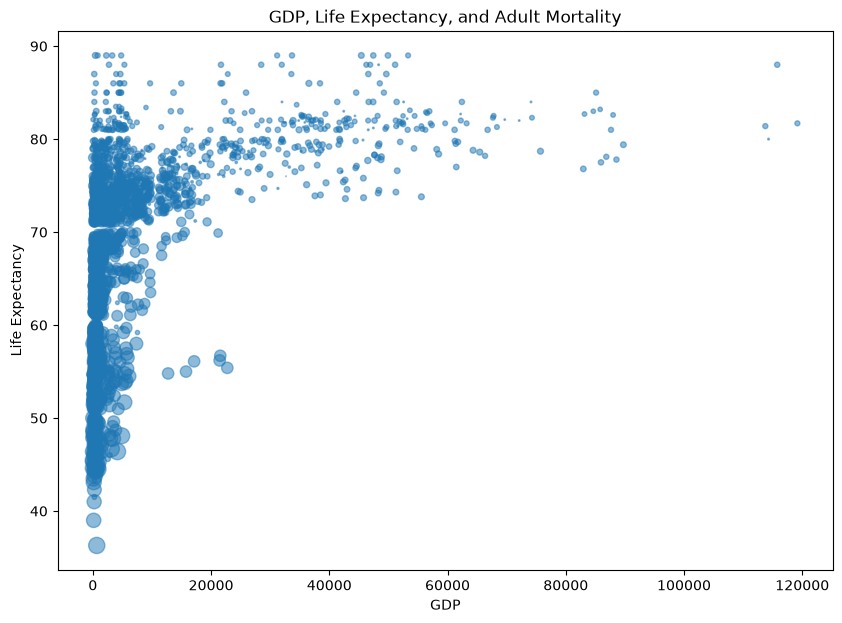

In [30]:
plt.figure(figsize=(10, 7))

plt.scatter(
    life["GDP"],
    life["Life expectancy"],
    s=life["Adult Mortality"].clip(lower=0) / 5,
    alpha=0.5
)

plt.xlabel("GDP")
plt.ylabel("Life Expectancy")
plt.title("GDP, Life Expectancy, and Adult Mortality")
plt.show()

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Select numerical columns
pca_data = life_numeric.dropna()

# Standardize the data
scaler = StandardScaler()
scaled_data = scaler.fit_transform(pca_data)

# Perform PCA
pca = PCA()
pca_result = pca.fit_transform(scaled_data)

# Explained variance
print(pca.explained_variance_ratio_)

print("First principal component:",
      pca.explained_variance_ratio_[0])

print("First two components:",
      pca.explained_variance_ratio_[:2].sum())

[3.06783703e-01 1.44944872e-01 9.23776950e-02 7.95648782e-02
 6.45367651e-02 5.09350056e-02 4.23709875e-02 3.99727330e-02
 3.28583237e-02 2.59053504e-02 2.51791359e-02 2.08426600e-02
 1.90921523e-02 1.72876805e-02 1.54903643e-02 1.01367493e-02
 6.13468392e-03 3.54049290e-03 1.93082031e-03 1.14947084e-04]
First principal component: 0.3067837029147145
First two components: 0.45172857491845364


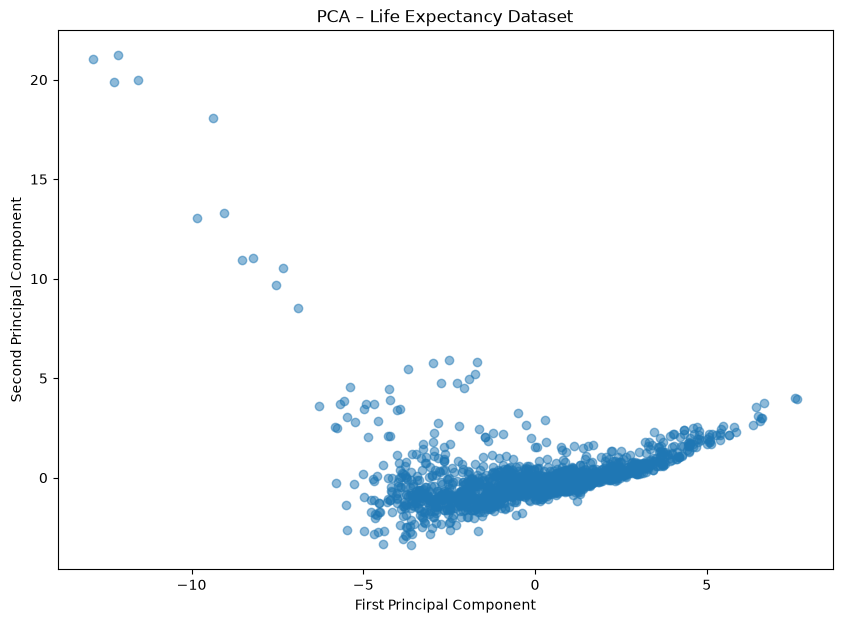

In [32]:
plt.figure(figsize=(10, 7))

plt.scatter(
    pca_result[:, 0],
    pca_result[:, 1],
    alpha=0.5
)

plt.xlabel("First Principal Component")
plt.ylabel("Second Principal Component")
plt.title("PCA – Life Expectancy Dataset")
plt.show()

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

features = [
    "GDP",
    "Schooling",
    "Adult Mortality",
    "Income composition of resources"
]

regression_data = life[features + ["Life expectancy"]].dropna()

X = regression_data[features]
y = regression_data["Life expectancy"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("R-squared:", r2_score(y_test, predictions))
print("Mean Squared Error:", mean_squared_error(y_test, predictions))

R-squared: 0.7343221440093117
Mean Squared Error: 22.973573669935202


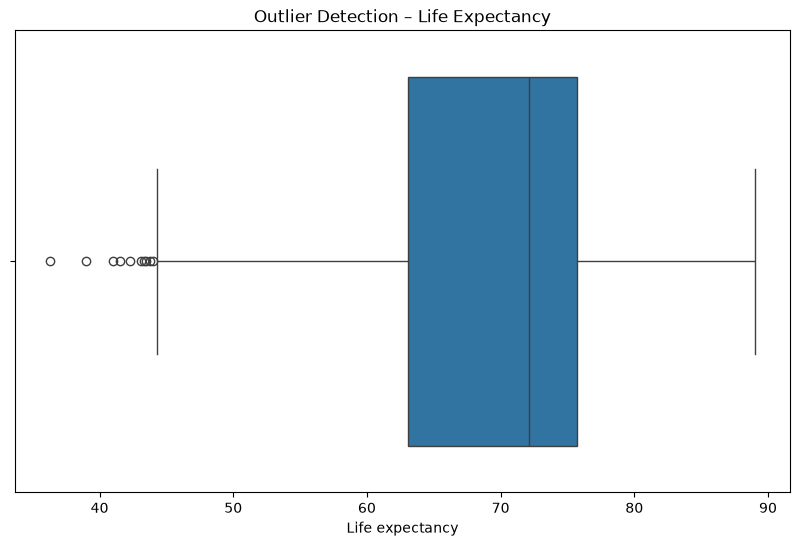

In [34]:
plt.figure(figsize=(10, 6))

sns.boxplot(x=life["Life expectancy"])

plt.title("Outlier Detection – Life Expectancy")
plt.show()

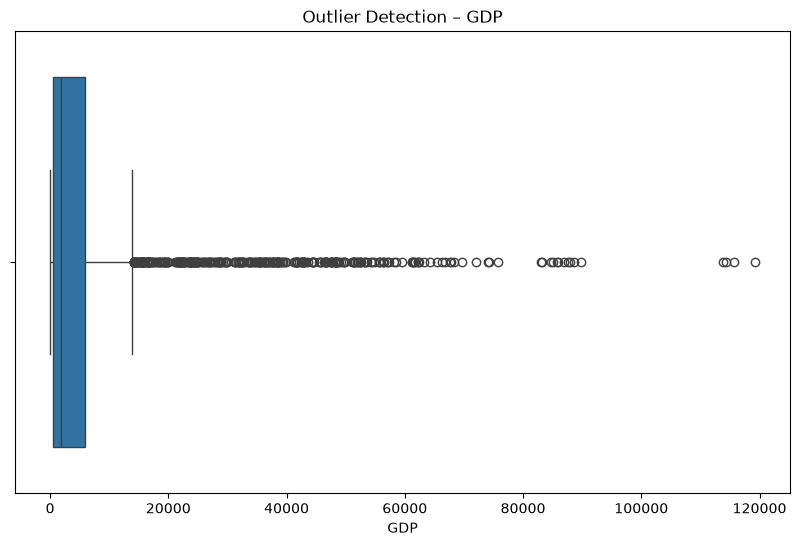

In [35]:
plt.figure(figsize=(10, 6))

sns.boxplot(x=life["GDP"])

plt.title("Outlier Detection – GDP")
plt.show()

# 4. Storytelling With Data plot

Reproduce any graph of your choice in p. 136-150 of the Storytelling With Data book as best you can. ("The power of super-categories" to the end of chapter 5). You do not have to get the exact data values right, just the overall look and feel.

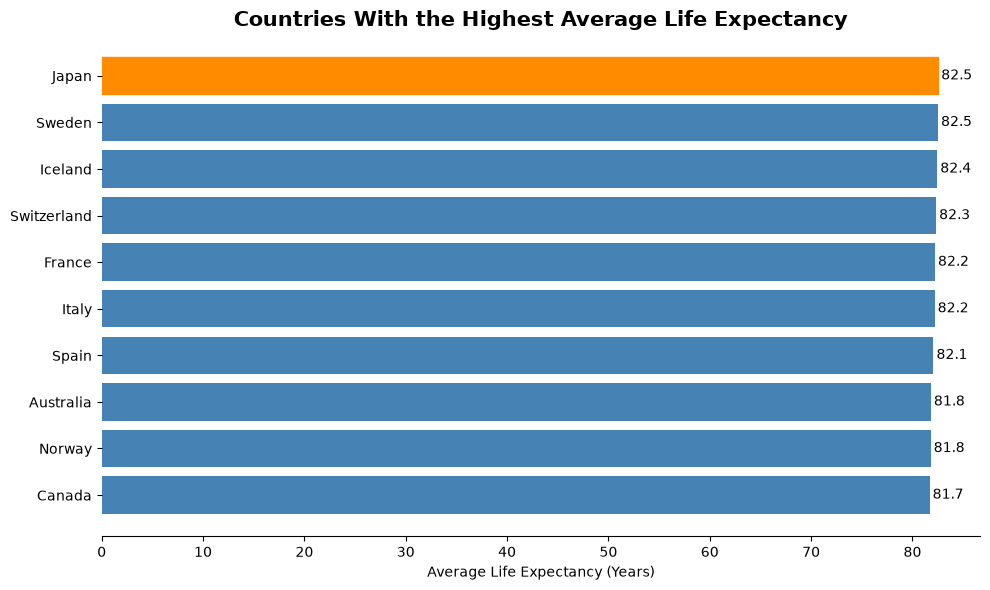

In [36]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
life = pd.read_csv("Life Expectancy Data.csv")
life.columns = life.columns.str.strip()

# Calculate average life expectancy by country
country_life = (
    life.groupby("Country")["Life expectancy"]
    .mean()
    .sort_values(ascending=False)
)

# Select top 10 countries
top_10 = country_life.head(10).sort_values()

# Create visualization
plt.figure(figsize=(10, 6))

bars = plt.barh(
    top_10.index,
    top_10.values,
    color="steelblue"
)

# Highlight the country with the highest life expectancy
bars[-1].set_color("darkorange")

# Add value labels
for bar in bars:
    plt.text(
        bar.get_width() + 0.3,
        bar.get_y() + bar.get_height()/2,
        f'{bar.get_width():.1f}',
        va='center'
    )

plt.title(
    "Countries With the Highest Average Life Expectancy",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Average Life Expectancy (Years)")
plt.ylabel("")

# Remove unnecessary borders
plt.gca().spines["top"].set_visible(False)
plt.gca().spines["right"].set_visible(False)
plt.gca().spines["left"].set_visible(False)

plt.tight_layout()
plt.show()